## Лабораторна робота № 4 Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропусків

In [1]:
from sklearn.datasets import fetch_openml

data = fetch_openml(
    name="anneal",
    version=1,
    as_frame=True
)

X = data.data
y = data.target

## Імпорти та налаштування

In [4]:
import sys, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, optuna, shap, scipy

from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, cross_validate,
    StratifiedKFold, cross_val_score, cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from scipy.stats import t as student_t, chi2_contingency

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme()

N = 21
SEED = 42 + N
N_TRIALS = 10  



##  Завантаження Annealing з OpenML

In [5]:
data = fetch_openml(name="anneal", version=1, as_frame=True)
X = data.data.copy()
y_raw = data.target.copy()

# Категоріальні ознаки приводимо до object; зберігаємо пропуски як NaN.
for col in X.columns:
    if (pd.api.types.is_object_dtype(X[col]) or
        isinstance(X[col].dtype, pd.CategoricalDtype) or
        pd.api.types.is_string_dtype(X[col])):
        X[col] = X[col].astype("object")

print("Розмір X:", X.shape)
print("Кількість міток y:", len(y_raw))
print("Назва датасету:", getattr(data, "details", {}).get("name", "anneal"))
display(X.head())
display(y_raw.value_counts(dropna=False).rename("count").to_frame())

Розмір X: (898, 38)
Кількість міток y: 898
Назва датасету: anneal


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,...,jurofm,s,p,shape,thick,width,len,oil,bore,packing
0,NaN,C,A,8,0,NaN,S,NaN,0,NaN,...,NaN,NaN,NaN,COIL,0.700,610.0,0,NaN,0,NaN
1,NaN,C,R,0,0,NaN,S,2,0,NaN,...,NaN,NaN,NaN,COIL,3.200,610.0,0,NaN,0,NaN
2,NaN,C,R,0,0,NaN,S,2,0,NaN,...,NaN,NaN,NaN,SHEET,0.700,1300.0,762,NaN,0,NaN
3,NaN,C,A,0,60,T,NaN,NaN,0,NaN,...,NaN,NaN,NaN,COIL,2.801,385.1,0,NaN,0,NaN
4,NaN,C,A,0,60,T,NaN,NaN,0,NaN,...,NaN,NaN,NaN,SHEET,0.801,255.0,269,NaN,0,NaN


,count
class,
3,684
2,99
5,67
U,40
1,8


## Первинний аналіз

Типи ознак:


,кількість
dtype,
object,32
int64,4
float64,2


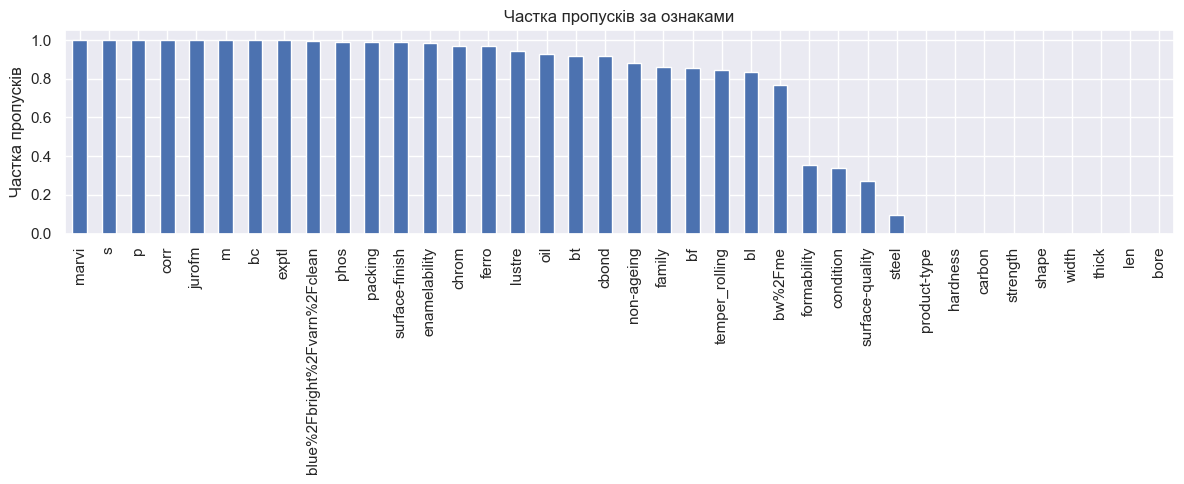

Повністю порожні ознаки: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні (не враховуючи NaN) ознаки: ['product-type', 'temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'lustre']
Видалені ознаки: ['bc', 'bf', 'bl', 'bt', 'cbond', 'chrom', 'corr', 'exptl', 'ferro', 'jurofm', 'lustre', 'm', 'marvi', 'non-ageing', 'p', 'phos', 'product-type', 's', 'surface-finish', 'temper_rolling']
Новий розмір X: (898, 18)


In [6]:
print("Типи ознак:")
display(X.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("кількість"))

missing_rate = X.isna().mean().sort_values(ascending=False)
plt.figure(figsize=(12, 5))
missing_rate.plot(kind="bar")
plt.ylabel("Частка пропусків")
plt.title("Частка пропусків за ознаками")
plt.tight_layout()
plt.show()

all_missing = X.columns[X.isna().all()].tolist()
constant = [c for c in X.columns if X[c].nunique(dropna=True) <= 1 and c not in all_missing]
print("Повністю порожні ознаки:", all_missing)
print("Константні (не враховуючи NaN) ознаки:", constant)

# Видаляємо ознаки, які не містять корисної варіації.
drop_cols = sorted(set(all_missing + constant))
X = X.drop(columns=drop_cols)
print("Видалені ознаки:", drop_cols)
print("Новий розмір X:", X.shape)

Велика частка пропусків сама по собі не доводить MCAR, MAR чи MNAR. Далі перевіряємо, чи пов'язаний факт пропуску з цільовим класом. Такий тест може виявити залежність від класу, але не дозволяє однозначно розрізнити MAR і MNAR.

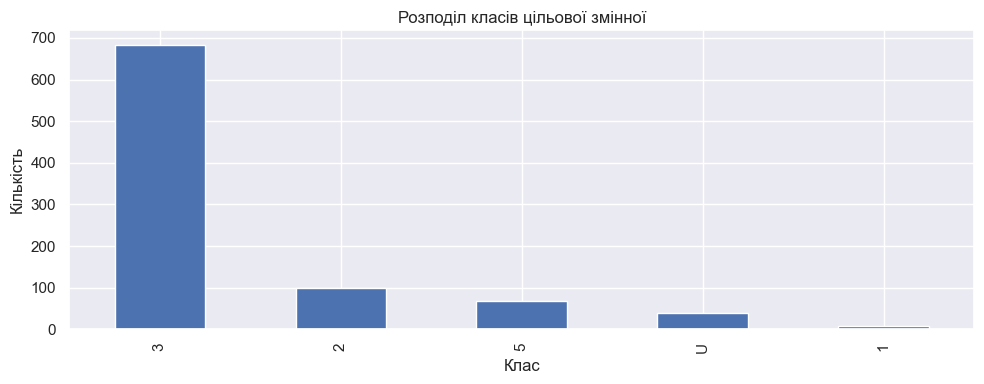

,count
class,
3,684
2,99
5,67
U,40
1,8


Мінімальна кількість об'єктів у класі: 8


In [7]:
plt.figure(figsize=(10, 4))
y_raw.value_counts().plot(kind="bar")
plt.title("Розподіл класів цільової змінної")
plt.xlabel("Клас")
plt.ylabel("Кількість")
plt.tight_layout()
plt.show()

class_counts = y_raw.value_counts()
display(class_counts.rename("count").to_frame())
print("Мінімальна кількість об'єктів у класі:", int(class_counts.min()))

# Аналіз залежності пропусків від класу (χ²)

In [8]:
miss_cols = [c for c in X.columns if 0 < X[c].isna().mean() < 1]
top_missing = sorted(miss_cols, key=lambda c: X[c].isna().mean(), reverse=True)[:5]

missing_test_results = []
for col in top_missing:
    tab = pd.crosstab(X[col].isna().map({True: "пропуск", False: "є значення"}), y_raw)
    chi2, p, dof, expected = chi2_contingency(tab)
    missing_test_results.append({
        "ознака": col, "частка пропусків": X[col].isna().mean(),
        "chi2": chi2, "dof": dof, "p-value": p,
        "висновок (α=0.05)": "є зв'язок із класом" if p < 0.05 else "немає достатніх доказів зв'язку"
    })
    print(f"\nОзнака: {col}")
    display(tab)

display(pd.DataFrame(missing_test_results))


Ознака: blue%2Fbright%2Fvarn%2Fclean


class,1,2,3,5,U
blue%2Fbright%2Fvarn%2Fclean,,,,,
пропуск,7,95,683,67,40
є значення,1,4,1,0,0



Ознака: packing


class,1,2,3,5,U
packing,,,,,
пропуск,8,99,675,67,40
є значення,0,0,9,0,0



Ознака: enamelability


...


Ознака: oil


class,1,2,3,5,U
oil,,,,,
пропуск,8,99,628,67,32
є значення,0,0,56,0,8



Ознака: family


class,1,2,3,5,U
family,,,,,
пропуск,6,99,638,0,29
є значення,2,0,46,67,11


,ознака,частка пропусків,chi2,dof,p-value,висновок (α=0.05)
0,blue%2Fbright%2Fvarn%2Fclean,0.993318,37.365354,4,1.514610e-07,є зв'язок із класом
1,packing,0.989978,2.844296,4,5.842109e-01,немає достатніх доказів зв'язку
2,enamelability,0.982183,44.437628,4,5.203932e-09,є зв'язок із класом
3,oil,0.928731,24.528546,4,6.257161e-05,є зв'язок із класом
4,family,0.859688,463.747626,4,4.630236e-99,є зв'язок із класом


мале p-value свідчить, що статус пропуску пов'язаний із цільовим класом, тобто дані не схожі на MCAR для цієї ознаки. Велике p-value не доводить MCAR; особливо обережно слід трактувати результати за рідкісних класів.

## Кодування цільової змінної та train/test split

In [9]:
label_encoder = LabelEncoder()
y_enc = pd.Series(label_encoder.fit_transform(y_raw.astype(str)), index=y_raw.index, name="target")
class_names = list(label_encoder.classes_)
print("Кодування класів:", {i: name for i, name in enumerate(class_names)})
print("Кількості класів:", y_enc.value_counts().sort_index().to_dict())

min_count = int(y_enc.value_counts().min())
if min_count < 5:
    print("УВАГА: мінімальний клас має менше 5 прикладів. 5-fold CV може бути нестабільною;")
    print("якщо виникнуть помилки, обґрунтуйте об'єднання/виключення класу у звіті.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Кодування класів: {0: '1', 1: '2', 2: '3', 3: '5', 4: 'U'}
Кількості класів: {0: 8, 1: 99, 2: 684, 3: 67, 4: 40}
Train: (718, 18) Test: (180, 18)


## Preprocessing та моделі
Варіант A: медіана для числових, мода + One-Hot Encoding для категоріальних.

Варіант B: те саме плюс індикатори пропусків. Усі imputers навчаються всередині Pipeline, тому валідаційні дані не впливають на їхні параметри.

In [10]:
def build_preprocessor(with_indicators: bool):
    numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
    categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

    transformers = [
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_cols)
    ]
    if with_indicators:
        transformers.append((
            "miss",
            MissingIndicator(features="missing-only", error_on_new=False),
            X_train.columns.tolist()
        ))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=True)

def make_model(name, params=None):
    params = dict(params or {})
    if name == "DT":
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == "RF":
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    if name == "XGB":
        return XGBClassifier(
            random_state=SEED, n_jobs=-1, eval_metric="mlogloss",
            tree_method="hist", **params
        )
    raise ValueError("Невідома модель: " + name)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([
        ("prep", build_preprocessor(with_indicators)),
        ("clf", make_model(name, params))
    ])

models = ["DT", "RF", "XGB"]
scoring = {"acc": "accuracy", "f1m": "f1_macro", "bacc": "balanced_accuracy"}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

Базові моделі — варіант A (без індикаторів)

In [11]:
baseline_A = {}
for name in models:
    pipe = build_pipeline(name, with_indicators=False)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score="raise")
    baseline_A[name] = res
    print(name, "готово")

def summarize_cv(results, variant):
    rows = []
    for name, res in results.items():
        for metric, key in [("Accuracy", "test_acc"), ("Macro F1", "test_f1m"), ("Balanced accuracy", "test_bacc")]:
            vals = res[key]
            rows.append({"Варіант": variant, "Модель": name, "Метрика": metric,
                         "Середнє": np.mean(vals), "Стандартне відхилення": np.std(vals, ddof=1)})
    return pd.DataFrame(rows)

table_A = summarize_cv(baseline_A, "A")
display(table_A.round(4))

DT готово
RF готово
XGB готово


,Варіант,Модель,Метрика,Середнє,Стандартне відхилення
0,A,DT,Accuracy,0.9434,0.0114
1,A,DT,Macro F1,0.8786,0.0771
2,A,DT,Balanced accuracy,0.8919,0.0810
3,A,RF,Accuracy,0.9434,0.0161
4,A,RF,Macro F1,0.8895,0.0818
5,A,RF,Balanced accuracy,0.8903,0.0841
6,A,XGB,Accuracy,0.9494,0.0146
7,A,XGB,Macro F1,0.8979,0.0859
8,A,XGB,Balanced accuracy,0.8966,0.0846


Базові моделі — варіант B (з індикаторами пропусків)

In [12]:
baseline_B = {}
for name in models:
    pipe = build_pipeline(name, with_indicators=True)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score="raise")
    baseline_B[name] = res
    print(name, "готово")

table_B = summarize_cv(baseline_B, "B")
display(table_B.round(4))

DT готово
RF готово
XGB готово


,Варіант,Модель,Метрика,Середнє,Стандартне відхилення
0,B,DT,Accuracy,0.9907,0.0086
1,B,DT,Macro F1,0.9418,0.0830
2,B,DT,Balanced accuracy,0.9495,0.0860
3,B,RF,Accuracy,0.9949,0.0049
4,B,RF,Macro F1,0.9505,0.0793
5,B,RF,Balanced accuracy,0.9471,0.0785
6,B,XGB,Accuracy,0.9893,0.0090
7,B,XGB,Macro F1,0.9429,0.0823
8,B,XGB,Balanced accuracy,0.9402,0.0815


## Optuna: підбір гіперпараметрів

In [13]:
def suggest_params(trial, name):
    if name == "DT":
        return {
            "max_depth": trial.suggest_int("max_depth", 2, 20),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
    if name == "RF":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_int("max_depth", 3, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
        }
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 400),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 10, log=True),
    }

def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring="f1_macro", n_jobs=1).mean()
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    return study

## Вкладена крос-валідація (nested CV)

In [14]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_results = {}
for name in models:
    scores = []
    for fold, (tr_idx, va_idx) in enumerate(outer.split(X_train, y_train), start=1):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        study = tune(name, X_tr, y_tr, n_trials=N_TRIALS)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        pred = model.predict(X_va)
        scores.append(f1_score(y_va, pred, average="macro", zero_division=0))
        print(f"{name}: fold {fold}/5, macro F1={scores[-1]:.4f}")
    nested_results[name] = np.array(scores)

nested_table = pd.DataFrame([
    {"Модель": name, "Nested macro F1 mean": vals.mean(),
     "Nested macro F1 std": vals.std(ddof=1), "Fold scores": np.round(vals, 4).tolist()}
    for name, vals in nested_results.items()
])
display(nested_table)

[I 2026-10-20 19:02:26,187] A new study created in memory with name: no-name-1eab3173-034d-402c-86ec-7fede6f42dcd
[I 2026-10-20 19:02:26,358] Trial 0 finished with value: 0.9205883335107773 and parameters: {'max_depth': 12, 'min_samples_split': 9, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-20 19:02:26,450] Trial 1 finished with value: 0.7493921278284509 and parameters: {'max_depth': 11, 'min_samples_split': 6, 'min_samples_leaf': 6, 'class_weight': None}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-20 19:02:26,613] Trial 2 finished with value: 0.566175808886694 and parameters: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 8, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-20 19:02:26,685] Trial 3 finished with value: 0.9122956505839479 and parameters: {'max_depth': 10, 'min_samples_split': 12, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 

DT: fold 1/5, macro F1=0.7793


[I 2026-10-20 19:02:27,447] Trial 2 finished with value: 0.5446711765110381 and parameters: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 8, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8777044976570662.
[I 2026-10-20 19:02:27,533] Trial 3 finished with value: 0.8759234619076898 and parameters: {'max_depth': 10, 'min_samples_split': 12, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.8777044976570662.
[I 2026-10-20 19:02:27,608] Trial 4 finished with value: 0.7429651434975443 and parameters: {'max_depth': 19, 'min_samples_split': 18, 'min_samples_leaf': 7, 'class_weight': None}. Best is trial 0 with value: 0.8777044976570662.
[I 2026-10-20 19:02:27,679] Trial 5 finished with value: 0.763209171180474 and parameters: {'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 10, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8777044976570662.
[I 2026-10-20 19:02:27,746] Trial 6 finished with value: 0.748651482580570

DT: fold 2/5, macro F1=0.9837


[I 2026-10-20 19:02:28,271] Trial 2 finished with value: 0.59084045395091 and parameters: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 8, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8404542194182679.
[I 2026-10-20 19:02:28,384] Trial 3 finished with value: 0.8404542194182679 and parameters: {'max_depth': 10, 'min_samples_split': 12, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.8404542194182679.
[I 2026-10-20 19:02:28,463] Trial 4 finished with value: 0.7897548223419072 and parameters: {'max_depth': 19, 'min_samples_split': 18, 'min_samples_leaf': 7, 'class_weight': None}. Best is trial 0 with value: 0.8404542194182679.
[I 2026-10-20 19:02:28,573] Trial 5 finished with value: 0.8063582455510309 and parameters: {'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 10, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8404542194182679.
[I 2026-10-20 19:02:28,716] Trial 6 finished with value: 0.7904063366132673

...

[I 2026-10-20 19:04:25,019] Trial 0 finished with value: 0.7678870680573789 and parameters: {'n_estimators': 244, 'max_depth': 5, 'learning_rate': 0.01177847538567836, 'subsample': 0.8102690244371411, 'colsample_bytree': 0.6612154327247561, 'min_child_weight': 3.162351647432892}. Best is trial 0 with value: 0.7678870680573789.
[I 2026-10-20 19:04:25,531] Trial 1 finished with value: 0.7668373118621291 and parameters: {'n_estimators': 139, 'max_depth': 6, 'learning_rate': 0.06454394974493431, 'subsample': 0.6903154855426596, 'colsample_bytree': 0.635698524381078, 'min_child_weight': 2.8305421423639427}. Best is trial 0 with value: 0.7678870680573789.
[I 2026-10-20 19:04:26,411] Trial 2 finished with value: 0.8860036848604808 and parameters: {'n_estimators': 321, 'max_depth': 8, 'learning_rate': 0.18770994246510372, 'subsample': 0.7815379985416411, 'colsample_bytree': 0.8277759846109267, 'min_child_weight': 1.0122135408057693}. Best is trial 2 with value: 0.8860036848604808.
[I 2026-10-2

XGB: fold 4/5, macro F1=0.9930


[I 2026-10-20 19:04:33,023] Trial 0 finished with value: 0.7674838576848076 and parameters: {'n_estimators': 244, 'max_depth': 5, 'learning_rate': 0.01177847538567836, 'subsample': 0.8102690244371411, 'colsample_bytree': 0.6612154327247561, 'min_child_weight': 3.162351647432892}. Best is trial 0 with value: 0.7674838576848076.
[I 2026-10-20 19:04:33,528] Trial 1 finished with value: 0.7571569059764824 and parameters: {'n_estimators': 139, 'max_depth': 6, 'learning_rate': 0.06454394974493431, 'subsample': 0.6903154855426596, 'colsample_bytree': 0.635698524381078, 'min_child_weight': 2.8305421423639427}. Best is trial 0 with value: 0.7674838576848076.
[I 2026-10-20 19:04:34,458] Trial 2 finished with value: 0.9726704196129593 and parameters: {'n_estimators': 321, 'max_depth': 8, 'learning_rate': 0.18770994246510372, 'subsample': 0.7815379985416411, 'colsample_bytree': 0.8277759846109267, 'min_child_weight': 1.0122135408057693}. Best is trial 2 with value: 0.9726704196129593.
[I 2026-10-2

XGB: fold 5/5, macro F1=0.7921


,Модель,Nested macro F1 mean,Nested macro F1 std,Fold scores
0,DT,0.880977,0.106215,"[0.7793, 0.9837, 0.8758, 0.993, 0.773]"
1,RF,0.922785,0.088920,"[0.9837, 0.993, 0.9809, 0.8572, 0.7991]"
2,XGB,0.947224,0.087576,"[0.9837, 1.0, 0.9673, 0.993, 0.7921]"


## Фінальний підбір на всій train-вибірці та графіки Optuna

[I 2026-10-20 19:05:31,692] A new study created in memory with name: no-name-6fa9be78-d922-4e5a-a3fa-7800a5922663


Optuna для DT...


[I 2026-10-20 19:05:31,913] Trial 0 finished with value: 0.8883954491213443 and parameters: {'max_depth': 12, 'min_samples_split': 9, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.8883954491213443.
[I 2026-10-20 19:05:32,011] Trial 1 finished with value: 0.7670925568184167 and parameters: {'max_depth': 11, 'min_samples_split': 6, 'min_samples_leaf': 6, 'class_weight': None}. Best is trial 0 with value: 0.8883954491213443.
[I 2026-10-20 19:05:32,089] Trial 2 finished with value: 0.5691044743558271 and parameters: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 8, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8883954491213443.
[I 2026-10-20 19:05:32,164] Trial 3 finished with value: 0.8848926860568377 and parameters: {'max_depth': 10, 'min_samples_split': 12, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.8883954491213443.
[I 2026-10-20 19:05:32,249] Trial 4 finished with value: 0.7560434213244532 and p

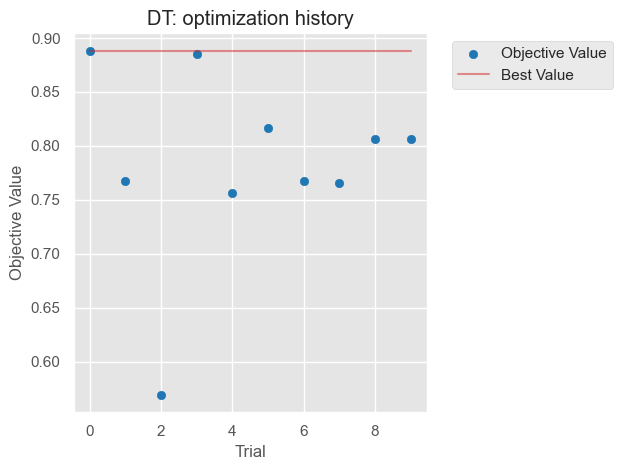

C:\Users\Богдан\AppData\Local\Temp\ipykernel_12252\2782251105.py:19: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


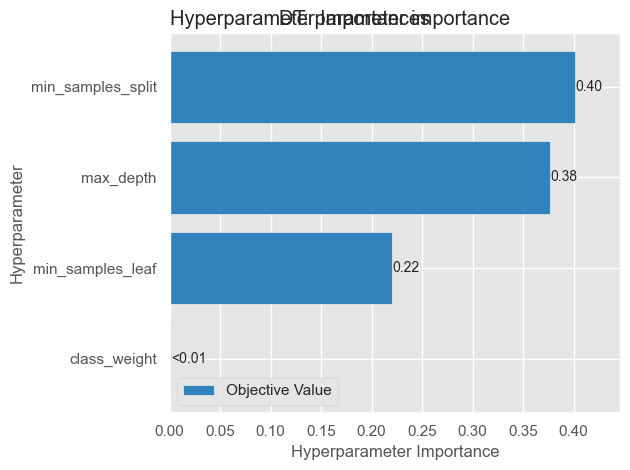

[I 2026-10-20 19:05:33,346] A new study created in memory with name: no-name-c5ab32fd-5375-4bc4-b6ae-238d000ccf6a


Optuna для RF...


[I 2026-10-20 19:05:35,180] Trial 0 finished with value: 0.9691516796504135 and parameters: {'n_estimators': 300, 'max_depth': 14, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.9691516796504135.
[I 2026-10-20 19:05:36,166] Trial 1 finished with value: 0.9381072663982449 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9691516796504135.
[I 2026-10-20 19:05:38,152] Trial 2 finished with value: 0.7935069671282973 and parameters: {'n_estimators': 450, 'max_depth': 19, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9691516796504135.
[I 2026-10-20 19:05:41,178] Trial 3 finished with value: 0.8605466876147939 and parameters: {'n_estimators': 500, 'max_depth': 21, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is tri

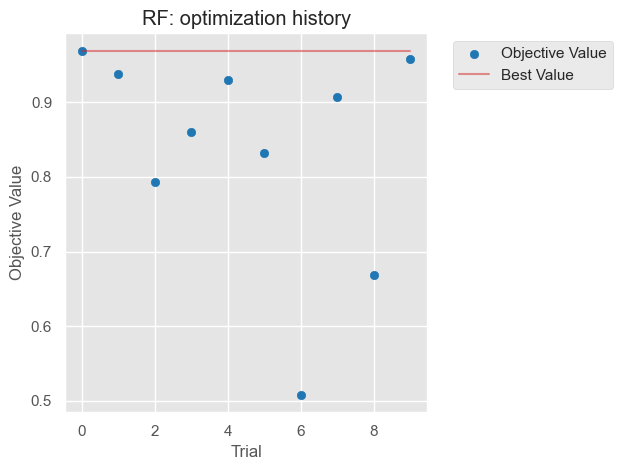

C:\Users\Богдан\AppData\Local\Temp\ipykernel_12252\2782251105.py:19: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


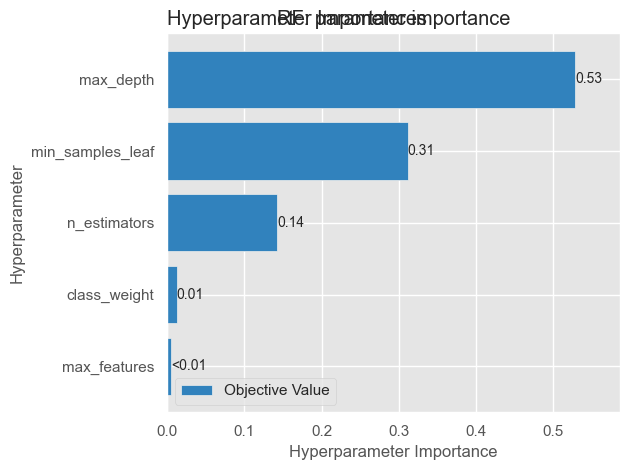

[I 2026-10-20 19:05:51,911] A new study created in memory with name: no-name-71eb2e34-3f9a-447c-a8f9-e16db33a9f21


Optuna для XGB...


[I 2026-10-20 19:05:52,705] Trial 0 finished with value: 0.7741182171491169 and parameters: {'n_estimators': 244, 'max_depth': 5, 'learning_rate': 0.01177847538567836, 'subsample': 0.8102690244371411, 'colsample_bytree': 0.6612154327247561, 'min_child_weight': 3.162351647432892}. Best is trial 0 with value: 0.7741182171491169.
[I 2026-10-20 19:05:53,183] Trial 1 finished with value: 0.7727024539786637 and parameters: {'n_estimators': 139, 'max_depth': 6, 'learning_rate': 0.06454394974493431, 'subsample': 0.6903154855426596, 'colsample_bytree': 0.635698524381078, 'min_child_weight': 2.8305421423639427}. Best is trial 0 with value: 0.7741182171491169.
[I 2026-10-20 19:05:54,039] Trial 2 finished with value: 0.9592726835893076 and parameters: {'n_estimators': 321, 'max_depth': 8, 'learning_rate': 0.18770994246510372, 'subsample': 0.7815379985416411, 'colsample_bytree': 0.8277759846109267, 'min_child_weight': 1.0122135408057693}. Best is trial 2 with value: 0.9592726835893076.
[I 2026-10-2

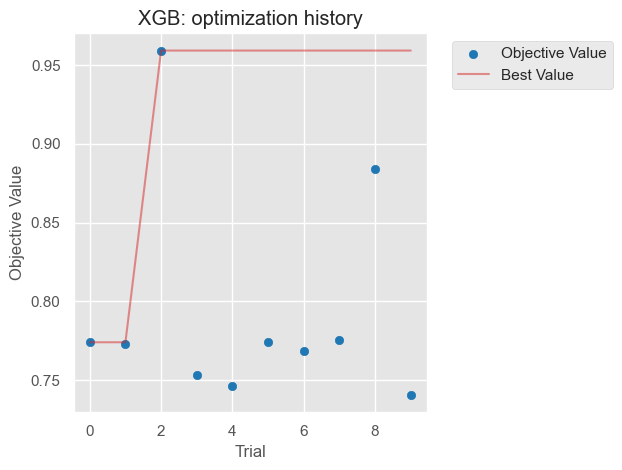

C:\Users\Богдан\AppData\Local\Temp\ipykernel_12252\2782251105.py:19: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


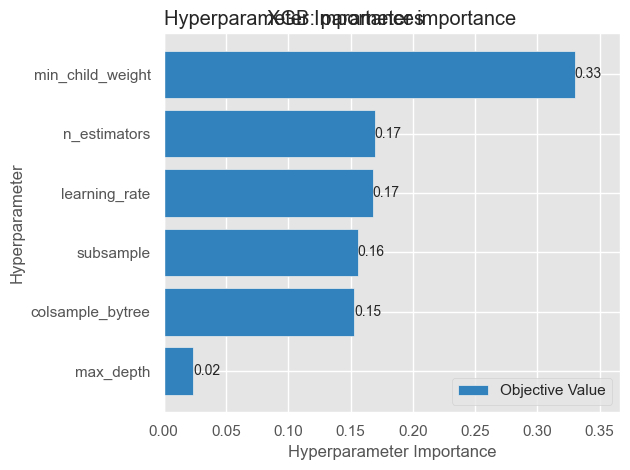

,Модель,Best CV macro F1 (best_value),Найкращі параметри
0,DT,0.888395,"{'max_depth': 12, 'min_samples_split': 9, 'min..."
1,RF,0.969152,"{'n_estimators': 300, 'max_depth': 14, 'min_sa..."
2,XGB,0.959273,"{'n_estimators': 321, 'max_depth': 8, 'learnin..."


In [15]:
studies = {}
final_models = {}
best_rows = []

for name in models:
    print(f"Optuna для {name}...")
    study = tune(name, X_train, y_train, n_trials=N_TRIALS)
    studies[name] = study
    final_models[name] = build_pipeline(name, True, study.best_params).fit(X_train, y_train)
    best_rows.append({"Модель": name, "Best CV macro F1 (best_value)": study.best_value,
                      "Найкращі параметри": study.best_params})

    try:
        from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
        plot_optimization_history(study)
        plt.title(f"{name}: optimization history")
        plt.tight_layout()
        plt.show()
        plot_param_importances(study)
        plt.title(f"{name}: parameter importance")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("Не вдалося побудувати графік Optuna:", e)

best_params_table = pd.DataFrame(best_rows)
display(best_params_table)

##  t-тест Наде–Бенжiо

In [18]:
def nadeau_bengio_test(scores1, scores2, n_splits=5, n_repeats=3):
    d = np.asarray(scores1) - np.asarray(scores2)
    n = len(d)
    mean_d = d.mean()
    var_d = d.var(ddof=1)
    
    ratio = 1 / (n_splits - 1)
    se = np.sqrt((1/n + ratio) * var_d)
    if se == 0:
        return mean_d, 0.0, 1.0
    t_stat = mean_d / se
    p_value = 2 * student_t.sf(abs(t_stat), df=n-1)
    return mean_d, t_stat, p_value

stat_rows = []
for name in models:
    d, t_stat, p = nadeau_bengio_test(
        baseline_B[name]["test_f1m"], baseline_A[name]["test_f1m"]
    )
    stat_rows.append({"Порівняння": f"{name}: B - A", "Середня різниця": d,
                      "t": t_stat, "p-value": p,
                      "Значуще при α=0.05": p < 0.05})


mean_B = {name: baseline_B[name]["test_f1m"].mean() for name in models}
top_two = sorted(mean_B, key=mean_B.get, reverse=True)[:2]
d, t_stat, p = nadeau_bengio_test(
    baseline_B[top_two[0]]["test_f1m"], baseline_B[top_two[1]]["test_f1m"]
)
stat_rows.append({"Порівняння": f"{top_two[0]} - {top_two[1]} (B)",
                  "Середня різниця": d, "t": t_stat, "p-value": p,
                  "Значуще при α=0.05": p < 0.05})
stat_table = pd.DataFrame(stat_rows)
display(stat_table.round(5))

,Порівняння,Середня різниця,t,p-value,Значуще при α=0.05
0,DT: B - A,0.06318,2.19505,0.04552,True
1,RF: B - A,0.06102,5.16403,0.00014,True
2,XGB: B - A,0.04502,3.28770,0.00539,True
3,RF - XGB (B),0.00760,1.53482,0.14711,False


## Фінальна оцінка на test

,Модель,Accuracy,Macro F1,Balanced accuracy
1,RF,0.9889,0.9885,0.9885
0,DT,0.9833,0.9832,0.9871
2,XGB,0.9778,0.7876,0.7971


Найкраща за test macro F1 модель: RF
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       0.95      0.95      0.95        20
           3       0.99      0.99      0.99       137
           5       1.00      1.00      1.00        13
           U       1.00      1.00      1.00         8

    accuracy                           0.99       180
   macro avg       0.99      0.99      0.99       180
weighted avg       0.99      0.99      0.99       180



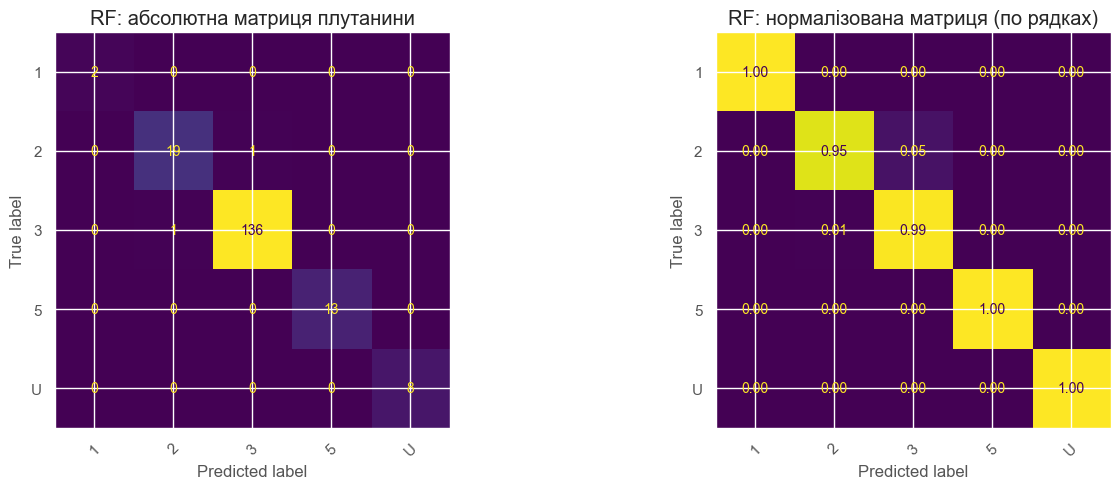

Найчастіші плутання (справжній клас -> прогнозований клас): [(np.int64(1), '3', '2'), (np.int64(1), '2', '3')]


In [19]:
test_rows = []
test_predictions = {}
for name, model in final_models.items():
    pred = model.predict(X_test)
    test_predictions[name] = pred
    test_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred)
    })
test_table = pd.DataFrame(test_rows).sort_values("Macro F1", ascending=False)
display(test_table.round(4))

best_name = test_table.iloc[0]["Модель"]
best_model = final_models[best_name]
best_pred = test_predictions[best_name]
print("Найкраща за test macro F1 модель:", best_name)
print(classification_report(y_test, best_pred, labels=np.arange(len(class_names)),
                            target_names=class_names, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, best_pred, labels=np.arange(len(class_names)))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title(f"{best_name}: абсолютна матриця плутанини")
cm_norm = confusion_matrix(y_test, best_pred, labels=np.arange(len(class_names)), normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(ax=axes[1], xticks_rotation=45, values_format=".2f", colorbar=False)
axes[1].set_title(f"{best_name}: нормалізована матриця (по рядках)")
plt.tight_layout()
plt.show()

# Найчастіші помилки між класами
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = []
for i, j in zip(*np.where(cm_off > 0)):
    pairs.append((cm_off[i, j], class_names[i], class_names[j]))
print("Найчастіші плутання (справжній клас -> прогнозований клас):",
      sorted(pairs, reverse=True)[:10])

## MDI та permutation importance



DT: top-15 MDI


,Ознака,MDI
45,miss__missingindicator_surface-quality,0.281351
41,miss__missingindicator_family,0.199679
0,num__carbon,0.195068
1,num__hardness,0.182195
2,num__strength,0.055261
3,num__thick,0.028079
8,cat__steel_A,0.025771
12,cat__steel_S,0.019166
44,miss__missingindicator_formability,0.007255
4,num__width,0.006175


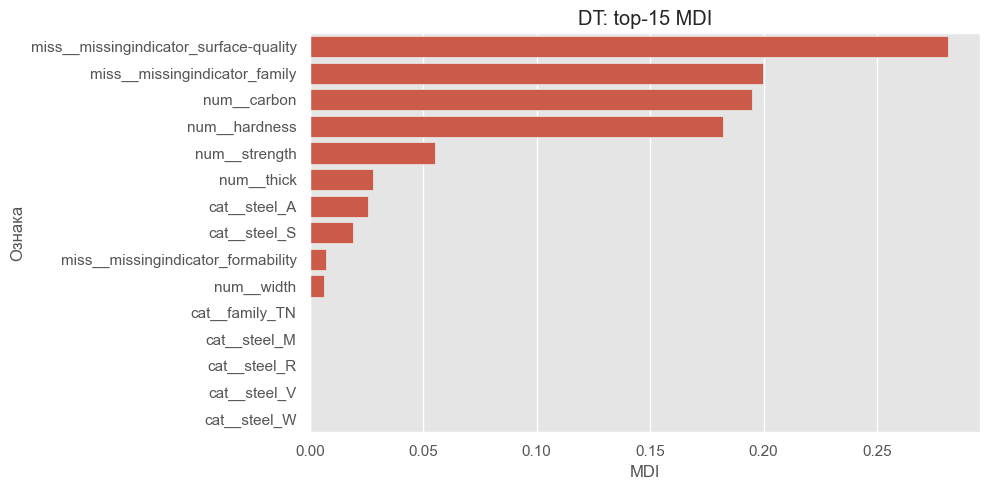

DT: top-15 permutation importance


,Ознака,Permutation mean,Permutation std
7,surface-quality,0.462050,0.111548
1,steel,0.269481,0.013109
3,hardness,0.204441,0.011059
0,family,0.181496,0.017255
12,thick,0.123396,0.077894
2,carbon,0.095145,0.016495
6,strength,0.090685,0.034884
5,formability,0.036428,0.009360
13,width,0.002811,0.005622
4,condition,0.000000,0.000000


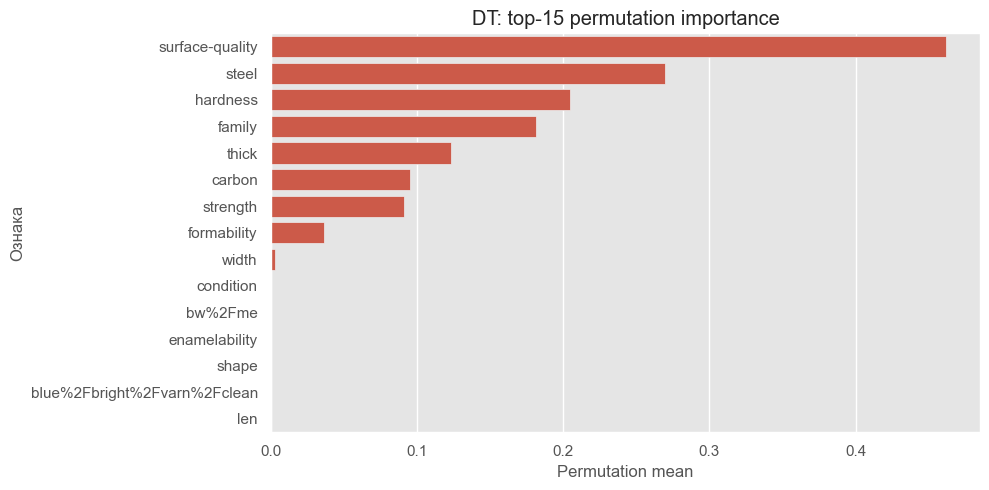

Індикатори пропусків у top-15 MDI: ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_formability']

RF: top-15 MDI


,Ознака,MDI
45,miss__missingindicator_surface-quality,0.134338
1,num__hardness,0.109986
41,miss__missingindicator_family,0.080325
44,miss__missingindicator_formability,0.068895
8,cat__steel_A,0.065991
3,num__thick,0.063022
2,num__strength,0.061265
43,miss__missingindicator_condition,0.057881
18,cat__formability_2,0.048154
11,cat__steel_R,0.032214


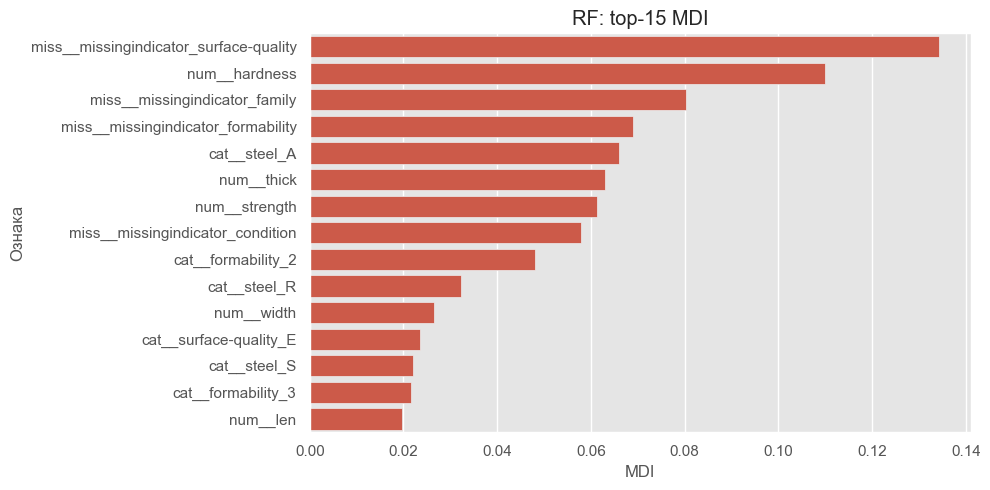

RF: top-15 permutation importance


,Ознака,Permutation mean,Permutation std
7,surface-quality,0.291131,0.081866
1,steel,0.291123,0.016343
6,strength,0.209462,0.038949
3,hardness,0.199283,0.015821
11,shape,0.094056,0.075849
13,width,0.071644,0.070377
5,formability,0.054876,0.018831
12,thick,0.051550,0.038817
14,len,0.022365,0.031914
8,enamelability,0.005372,0.000000


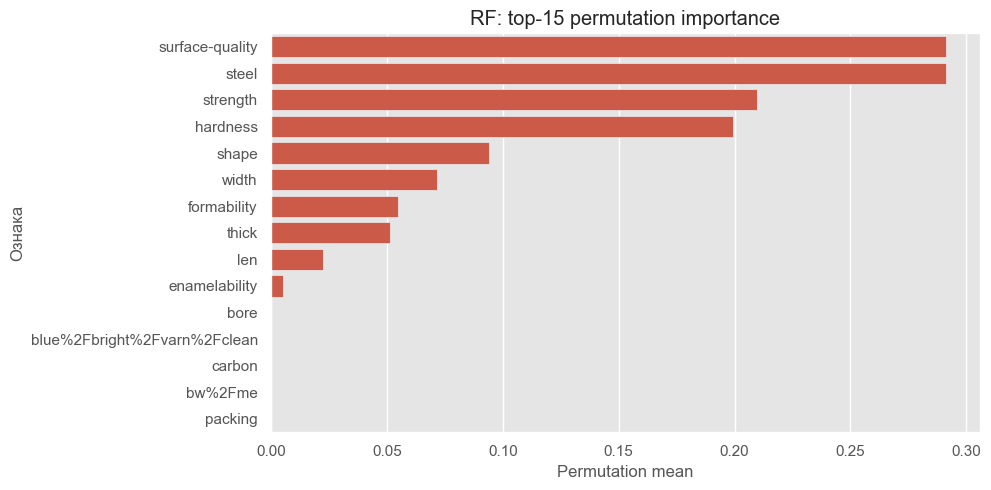

Індикатори пропусків у top-15 MDI: ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_formability', 'miss__missingindicator_condition']

XGB: top-15 MDI


,Ознака,MDI
7,cat__family_ZS,0.345795
41,miss__missingindicator_family,0.133473
9,cat__steel_K,0.099445
26,cat__enamelability_2,0.057588
45,miss__missingindicator_surface-quality,0.044778
6,cat__family_TN,0.037795
1,num__hardness,0.033506
21,cat__surface-quality_D,0.026896
25,cat__enamelability_1,0.020613
44,miss__missingindicator_formability,0.019368


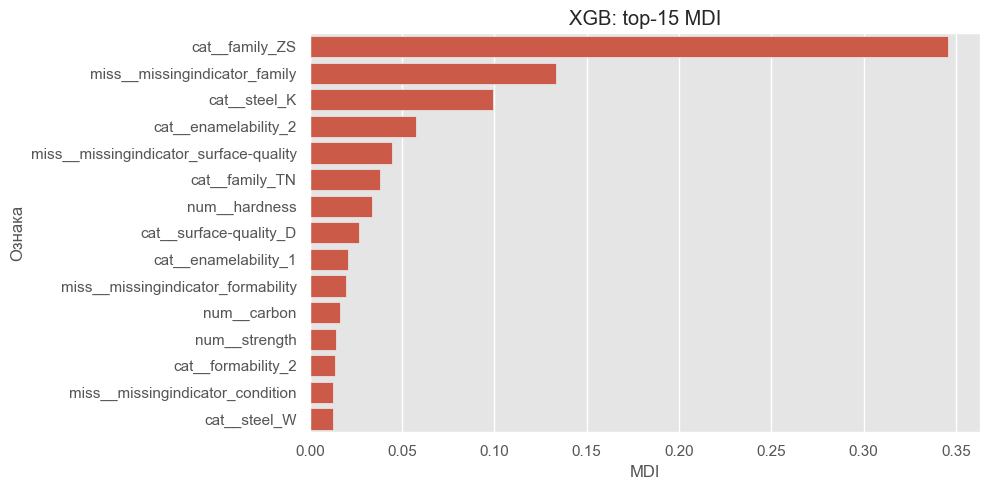

XGB: top-15 permutation importance


,Ознака,Permutation mean,Permutation std
3,hardness,0.210743,0.017554
7,surface-quality,0.167416,0.004876
0,family,0.113250,0.010656
6,strength,0.031252,0.003565
4,condition,0.007865,0.003877
2,carbon,0.001251,0.003752
14,len,0.000762,0.003930
16,bore,0.000000,0.000000
9,bw%2Fme,0.000000,0.000000
8,enamelability,0.000000,0.000000


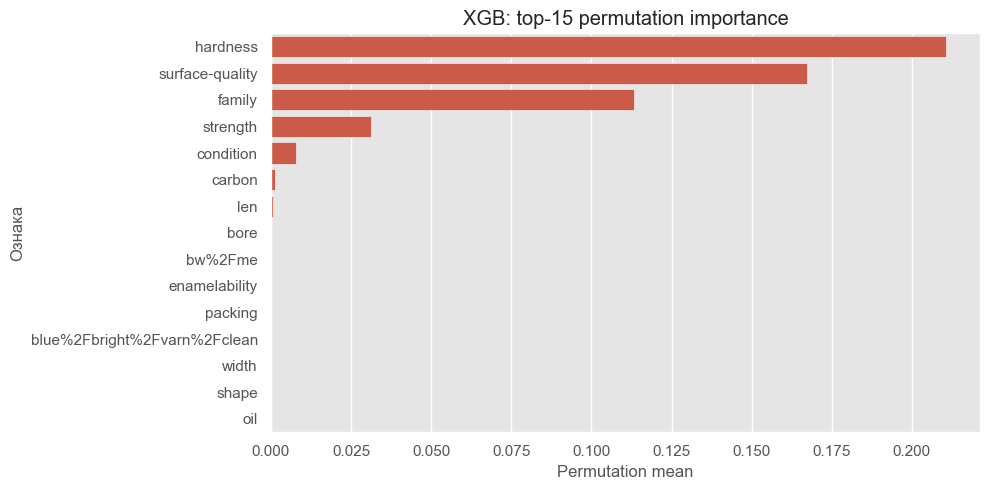

Індикатори пропусків у top-15 MDI: ['miss__missingindicator_family', 'miss__missingindicator_surface-quality', 'miss__missingindicator_formability', 'miss__missingindicator_condition']


In [20]:
importance_results = {}
for name, model in final_models.items():
    prep = model.named_steps["prep"]
    clf = model.named_steps["clf"]
    feature_names = prep.get_feature_names_out()
    mdi = getattr(clf, "feature_importances_", None)
    if mdi is not None:
        mdi_df = pd.DataFrame({"Ознака": feature_names, "MDI": mdi}).sort_values("MDI", ascending=False)
        importance_results[name] = {"mdi": mdi_df}
        print(f"\n{name}: top-15 MDI")
        display(mdi_df.head(15))
        plt.figure(figsize=(10, 5))
        sns.barplot(data=mdi_df.head(15), x="MDI", y="Ознака")
        plt.title(f"{name}: top-15 MDI")
        plt.tight_layout()
        plt.show()

    perm = permutation_importance(
        model, X_test, y_test, scoring="f1_macro",
        n_repeats=10, random_state=SEED, n_jobs=1
    )
    perm_df = pd.DataFrame({
        "Ознака": X_test.columns,
        "Permutation mean": perm.importances_mean,
        "Permutation std": perm.importances_std
    }).sort_values("Permutation mean", ascending=False)
    importance_results.setdefault(name, {})["permutation"] = perm_df
    print(f"{name}: top-15 permutation importance")
    display(perm_df.head(15))
    plt.figure(figsize=(10, 5))
    sns.barplot(data=perm_df.head(15), x="Permutation mean", y="Ознака")
    plt.title(f"{name}: top-15 permutation importance")
    plt.tight_layout()
    plt.show()

    if "mdi" in importance_results[name]:
        top_mdi = importance_results[name]["mdi"].head(15)["Ознака"].astype(str).tolist()
        print("Індикатори пропусків у top-15 MDI:",
              [f for f in top_mdi if "miss" in f.lower() or "missingindicator" in f.lower()])

## Розбіжності між трьома моделями

In [21]:
disagreement_rows = []
for pos, idx in enumerate(X_test.index):
    preds = {name: int(test_predictions[name][pos]) for name in models}
    if len(set(preds.values())) > 1:
        disagreement_rows.append({
            "Індекс об'єкта": idx,
            "Справжній клас": class_names[int(y_test.loc[idx])],
            "Decision Tree": class_names[preds["DT"]],
            "Random Forest": class_names[preds["RF"]],
            "XGBoost": class_names[preds["XGB"]],
            "Джерело": "test"
        })

if len(disagreement_rows) < 3:
    print("У test менше трьох розбіжностей; доповнюємо OOF-прогнозами train.")
    oof_preds = {}
    oof_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    for name in models:
        oof_preds[name] = cross_val_predict(
            build_pipeline(name, True, studies[name].best_params),
            X_train, y_train, cv=oof_cv, method="predict", n_jobs=1
        )
    for pos, idx in enumerate(X_train.index):
        preds = {name: int(oof_preds[name][pos]) for name in models}
        if len(set(preds.values())) > 1:
            disagreement_rows.append({
                "Індекс об'єкта": idx,
                "Справжній клас": class_names[int(y_train.loc[idx])],
                "Decision Tree": class_names[preds["DT"]],
                "Random Forest": class_names[preds["RF"]],
                "XGBoost": class_names[preds["XGB"]],
                "Джерело": "train OOF"
            })
        if len(disagreement_rows) >= 3:
            break

disagreement_table = pd.DataFrame(disagreement_rows).head(10)
display(disagreement_table)

,Індекс об'єкта,Справжній клас,Decision Tree,Random Forest,XGBoost,Джерело
0,746,3,2,3,2,test
1,288,1,1,1,3,test
2,406,1,1,1,3,test
3,682,2,3,3,2,test


аналіз одного об'єкта розбіжності та SHAP

Індекс: 746


,Початкове значення
family,NaN
steel,V
carbon,0
hardness,0
condition,S
formability,2
strength,0
surface-quality,NaN
enamelability,1
bw%2Fme,NaN


Пропущені ознаки: ['family', 'surface-quality', 'bw%2Fme', 'blue%2Fbright%2Fvarn%2Fclean', 'oil', 'packing']

 DT прогноз: 2
predict_proba: [0. 1. 0. 0. 0.]

 RF прогноз: 3
predict_proba: [0.0067 0.4962 0.4971 0.     0.    ]

 XGB прогноз: 2
predict_proba: [0.01   0.8592 0.1214 0.0067 0.0026]


,Після preprocessing
num__carbon,0.0
num__hardness,0.0
num__strength,0.0
num__thick,0.8
num__width,609.9
num__len,0.0
cat__family_TN,1.0
cat__family_ZS,0.0
cat__steel_A,0.0
cat__steel_K,0.0



DT: top-5 SHAP для прогнозованого класу


,Ознака,SHAP
0,miss__missingindicator_surface-quality,0.455821
1,num__carbon,0.206444
2,miss__missingindicator_family,0.138579
3,miss__missingindicator_formability,0.054656
4,num__thick,0.031453


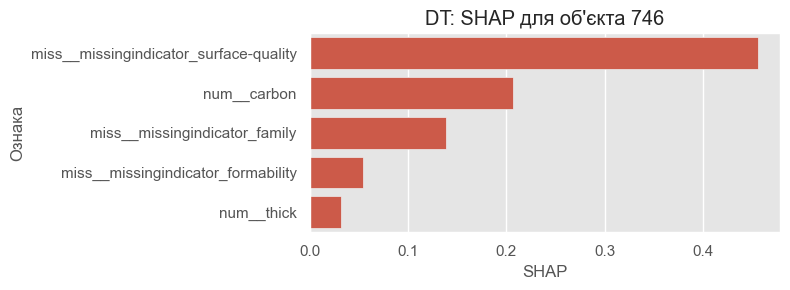


RF: top-5 SHAP для прогнозованого класу


,Ознака,SHAP
0,miss__missingindicator_surface-quality,-0.113640
1,cat__enamelability_2,0.067768
2,cat__enamelability_1,0.061111
3,miss__missingindicator_family,0.047668
4,num__hardness,0.046787


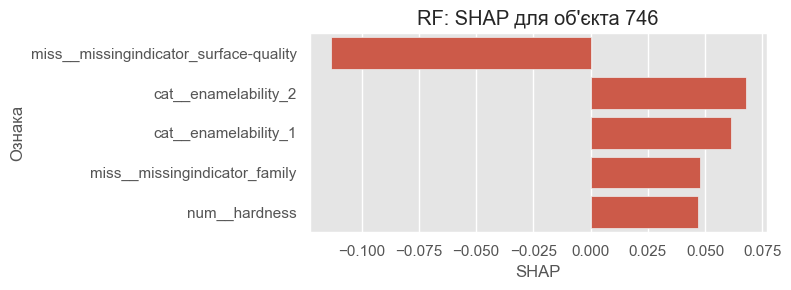


XGB: top-5 SHAP для прогнозованого класу


,Ознака,SHAP
0,miss__missingindicator_surface-quality,1.290429
1,miss__missingindicator_condition,1.250553
2,num__len,-0.808394
3,cat__steel_R,-0.573447
4,cat__steel_A,0.514368


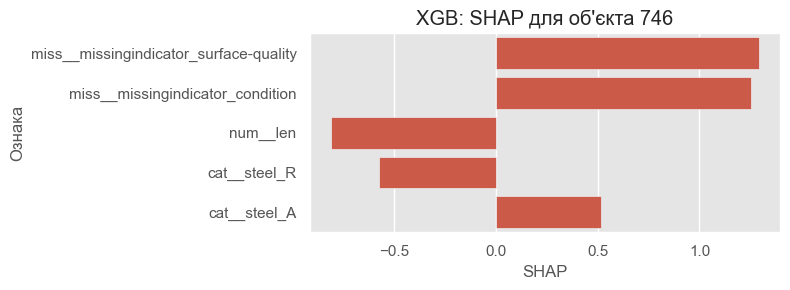

In [22]:
test_disagreements = disagreement_table[disagreement_table["Джерело"] == "test"] if len(disagreement_table) else pd.DataFrame()
if len(test_disagreements) == 0:
    print("Немає тестового об'єкта розбіжності. SHAP-пропуск: виберіть train OOF-об'єкт вручну або перевірте таблицю.")
else:
    obj_idx = test_disagreements.iloc[0]["Індекс об'єкта"]
    row_raw = X_test.loc[[obj_idx]]
    print("Індекс:", obj_idx)
    display(row_raw.T.rename(columns={obj_idx: "Початкове значення"}))
    print("Пропущені ознаки:", row_raw.columns[row_raw.isna().iloc[0]].tolist())

    # Для кожної моделі — прогноз і ймовірності
    for name, model in final_models.items():
        print("\n", name, "прогноз:", class_names[int(model.predict(row_raw)[0])])
        print("predict_proba:", np.round(model.predict_proba(row_raw)[0], 4))

    # Заповнення для демонстрації: трансформуємо рядок через навчений preprocessing.
    model_for_shap = final_models[best_name]
    prep = model_for_shap.named_steps["prep"]
    clf = model_for_shap.named_steps["clf"]
    transformed = prep.transform(row_raw)
    feature_names = prep.get_feature_names_out()
    filled = pd.DataFrame(transformed, columns=feature_names, index=[obj_idx])
    display(filled.T.rename(columns={obj_idx: "Після preprocessing"}))

    for name, model in final_models.items():
        prep_i = model.named_steps["prep"]
        clf_i = model.named_steps["clf"]
        Xt = prep_i.transform(row_raw)
        fn = prep_i.get_feature_names_out()
        try:
            explainer = shap.TreeExplainer(clf_i)
            sv = explainer.shap_values(Xt)
            # Нормалізуємо різні формати SHAP для багатокласової класифікації.
            if isinstance(sv, list):
                class_id = int(model.predict(row_raw)[0])
                vals = np.asarray(sv[class_id])[0]
            else:
                arr = np.asarray(sv)
                if arr.ndim == 3:
                    # Зазвичай (n_samples, n_features, n_classes)
                    class_id = int(model.predict(row_raw)[0])
                    if arr.shape[0] == 1:
                        vals = arr[0, :, class_id]
                    else:
                        vals = arr[0, :, class_id]
                elif arr.ndim == 2:
                    vals = arr[0]
                else:
                    raise ValueError(f"Невідомий формат SHAP: {arr.shape}")
            top_idx = np.argsort(np.abs(vals))[::-1][:5]
            top_df = pd.DataFrame({"Ознака": np.asarray(fn)[top_idx],
                                   "SHAP": np.asarray(vals)[top_idx]})
            print(f"\n{name}: top-5 SHAP для прогнозованого класу")
            display(top_df)
            plt.figure(figsize=(8, 3))
            sns.barplot(data=top_df, x="SHAP", y="Ознака")
            plt.title(f"{name}: SHAP для об'єкта {obj_idx}")
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"SHAP не вдалося обчислити для {name}: {e}")

In [26]:
import joblib
from pathlib import Path

Path("models_lab4").mkdir(exist_ok=True)
for name, model in final_models.items():
    joblib.dump(model, f"models_lab4/{name}_anneal_pipeline.joblib")


print("Збережено моделі у папку models_lab4/ ")

Збережено моделі у папку models_lab4/ 


1. За тестовою macro F1 найкращою виявилася модель RF (macro F1=0.9885, accuracy=0.9889).
2. За nested CV найкраща середня macro F1 у XGB (0.9472 ± 0.0876).
3. Вплив missing indicators оцінюється за таблицями A/B та скоригованим тестом Наде–Бенжiо.
4. Порівняйте best_value з nested CV: best_value зазвичай є оптимістичним, бо обраний як максимум внутрішньої CV.
5. Складні класи визначте за classification_report і нормалізованою матрицею плутанини.
6. Розбіжності моделей наведено в disagreement_table; поясніть їх через ймовірності та SHAP.
7. Практичний вибір має враховувати macro F1, стабільність, інтерпретованість і час навчання.

Контрольні питання — короткі відповіді
1. Decision Tree vs Random Forest: одне дерево легко інтерпретувати, але воно має високу дисперсію. Random Forest усереднює декорельовані дерева, зазвичай зменшуючи дисперсію без значного збільшення зміщення.
2. Беггінг vs бустинг: беггінг навчає моделі паралельно на bootstrap-вибірках і усереднює їх; бустинг послідовно додає моделі, що виправляють помилки попередніх. Бустинг може перенавчатися за надмірної складності/кількості ітерацій без регуляризації.
3. Macro F1 і balanced accuracy: надають однакову вагу класам, тому краще показують якість на рідкісних класах, ніж accuracy. Weighted F1 зважує внесок класів за їхньою підтримкою.
4. MCAR/MAR/MNAR: MCAR — пропуск не залежить від даних; MAR — залежить від спостережуваних змінних; MNAR — від самого відсутнього значення або неспостережуваних чинників. Індикатори можуть бути корисними, коли факт пропуску інформативний. За спостережуваними даними MAR і MNAR загалом неможливо однозначно розрізнити.
5. Витік даних: виникає, якщо імпутер/кодувальник навчається до поділу або до CV, або якщо тест використовують під час Optuna. Запобігання — Pipeline і налаштування лише на train-fold.
6. Nested CV: best_value — максимум внутрішньої CV і може бути оптимістичним. Зовнішній цикл оцінює процедуру вибору та навчання моделі на незалежному зовнішньому фолді.
7. Тест Наде–Бенжiо: звичайний парний t-тест не враховує залежність оцінок через перекриття тренувальних фолдів. Поправка збільшує оцінку дисперсії з урахуванням відношення розмірів test/train.
8. MDI vs permutation: MDI підсумовує зменшення неоднорідності в розбиттях і може бути упередженою до ознак із багатьма можливими розбиттями. Permutation importance оцінює падіння метрики при перемішуванні ознаки; корельовані ознаки можуть занижувати важливість одна одної.
9. SHAP: розкладає відхилення прогнозу від базового значення на внески ознак; локальне пояснення стосується одного об'єкта, глобальна важливість агрегує внески багатьох об'єктів.
10. XGBoost і NaN: алгоритм вивчає напрямок за замовчуванням для пропущених значень під час пошуку розбиттів, хоча в цій лабораторній роботі пропуски імпутуються для контрольованого порівняння.
11. Optuna: TPE використовує попередні результати для вибору перспективніших параметрів; pruning може зупиняти невдалі trial раніше. Це часто ефективніше за повний перебір, особливо у великих просторах пошуку.